# 15 — Predicciones tempranas: los primeros resultados reales

## El objetivo

> Predecir **cuántas solicitudes de triage llegarán al SES Hospital Universitario de Caldas**, como
> una **distribución** (un valor central y un rango). De ahí sale la **probabilidad de que el triage
> suba** por encima de lo que anuncia su calendario. Cada predicción lleva sus **razones**: qué del
> contexto interno y externo la mueve.

Es un solo proyecto. Los cuadernos 01-14 sirvieron para saber **con qué entrenar** y **cómo comprobar
la fiabilidad**. Este cuaderno junta las primeras predicciones reales, buenas o malas, para ver **cómo se
comporta hoy y qué falta**. No se espera que funcione a la primera. Si lo hiciera, habría que
sospechar.

## Lo que se decidió (docs/CONTEXTO.md, 2026-09-30 y 2026-10-01)

| | Decisión |
|---|---|
| **Qué se predice** | El conteo diario de triage a 1-7 días, el año completo y la hora de saturación |
| **Qué entrega** | Una **distribución** (9 cuantiles). La regresión es complemento, no método principal |
| **Qué es «subir»** | Pasar lo que anuncia el calendario. **Pico** = pasarlo en más de una desviación (≈ +11 %) |
| **Con qué se entrena** | **Todos los años con registro (2020-2026)**, con la COVID marcada, y **todo el contexto**: salud, clima, social, red de salud, catástrofes, eventos, ENSO. **Solo lo que se sabe el día de la predicción** |
| **Contra qué se prueba** | **2026**, con datos que el modelo nunca vio |
| **Qué modelos** | Todos en competencia: series de tiempo (SARIMAX, Prophet), modelo fundacional de series (Chronos-2), árboles (LightGBM), regresión binomial negativa, bases y MedGemma |
| **Confiabilidad esperada** | **60-70 %**. Por encima de eso hay que revisar el sobreentrenamiento o una fuga de información |

## Las tres pruebas

| Prueba | Pregunta | Cómo |
|---|---|---|
| **1. Corto plazo** | ¿Qué pasará los próximos 7 días? | Cada día de 2026, el modelo predice los 7 siguientes con lo que sabía hasta ayer |
| **2. El año a ciegas** | Desde diciembre de 2025: ¿cómo será cada mes de 2026? | Una sola predicción hecha el 31-12-2025 hasta septiembre |
| **3. La hora** | ¿A qué hora se satura el día predicho? | La predicción del día repartida con el perfil horario |

## Los tres experimentos, para saber qué aporta cada cosa

| | Años de entrenamiento | Contexto externo |
|---|---|---|
| **E0** | 2022-2024 (fase A) | no |
| **E1** | 2020-2025, con la COVID marcada | no |
| **E2** | 2020-2025, con la COVID marcada | **todo** |

E1 contra E0 dice qué aportan **más años**. E2 contra E1 dice qué aporta **el contexto**.

El motor está en `notebooks/pronostico.py` y las corridas largas escriben en `salidas/pronostico/`.

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "notebooks")); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import statsmodels.api as sm
from matplotlib import pyplot as plt
import pronostico as pr

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
COLOR = {"ingenuo": MUDO, "control": TINTA2, "glm_binneg": AZUL, "lightgbm": VERDE, "sarimax": VIOLETA,
         "prophet": AMARILLO, "chronos2": MAGENTA, "chronos2_cal": ROJO, "llm": NARANJA,
         "anio_pasado": MUDO, "regresion_anual": AZUL}
NOMBRE = {"ingenuo": "Ingenuo (semana pasada)", "control": "Control (calendario + nivel)", "glm_binneg": "Regresión binomial negativa",
          "lightgbm": "LightGBM (árboles)", "sarimax": "SARIMAX (serie de tiempo)", "prophet": "Prophet (serie de tiempo)",
          "chronos2": "Chronos-2 solo", "chronos2_cal": "Chronos-2 (IA de series)", "anio_pasado": "Igual que el año pasado",
          "regresion_anual": "Regresión anual (calendario + nivel)"}
CRIT = ["BSS sube %", "BSS pico %", "R2 desvio %", "acierta sube/baja %", "AUC pico", "cob80 %", "error <=10 %", "MAPE %", "n"]
SEM = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
color = lambda m: COLOR.get(m.split("_cada")[0], COLOR["llm"] if m.startswith("llm") else MUDO)

def leer(exp, desde="2025-12-31", modelos=None):
    P, U = pr.leer(exp=exp)
    P = P[(P.origen >= desde) & ~P.modelo.str.startswith("llm") & ~P.modelo.str.contains("_cada")]
    if modelos: P = P[P.modelo.isin(modelos)]
    return P, U

pr.usar("e2"); y, cal = pr.cargar()
print(f"triage diario: {y.notna().sum()} días con dato, {y.index[0].date()} a {y.index[-1].date()}")

triage diario: 2452 días con dato, 2020-01-01 a 2026-09-20


---
# 1. Los datos: qué se sabe y cuándo

La regla que manda sobre todas: **una predicción hecha el día *o* solo puede usar lo que se sabía el
día *o***. Lo que se sabe por adelantado (calendario, eventos programados) entra con el día que se
predice. Lo demás, con su último valor conocido.

,dato,fuente,¿cuándo se sabe?,capa
0,Triage diario,salidas/triage_diario.parquet,hasta el día de la predicción,nivel y memoria
1,Calendario de Colombia,calendario_Colombia.csv,por adelantado,calendario
2,COVID (dos fases),fechas fijas,por adelantado,calendario
3,"Feria, eventos de Manizales, fiestas de Caldas...","eventos_*, fiestas_*, calendario",por adelantado (programados),eventos
4,"IRA de Manizales (total, 0-4, 60+), consultas ...",Power BI 995 + microdatos,semana epidemiológica anterior,salud
5,"Agresión animal, intento de suicidio, varicela...",Power BI + microdatos,semana anterior,salud
6,"Temperatura, humedad, lluvia, radiación, vient...",clima_unificado.csv.gz,hasta el día anterior,clima
7,"Lesiones de tránsito, lesiones personales, hom...",seguridad_mindefensa.csv.gz,hasta el día anterior,social
8,Nueva EPS: cambio de 28 días y peso en el triage,triage_entidad.parquet,hasta el día de la predicción,red
9,Desastre activo (incluye el terremoto del 10-0...,desastres_manizales_2020_2026.csv,cuando ya empezó,catástrofe


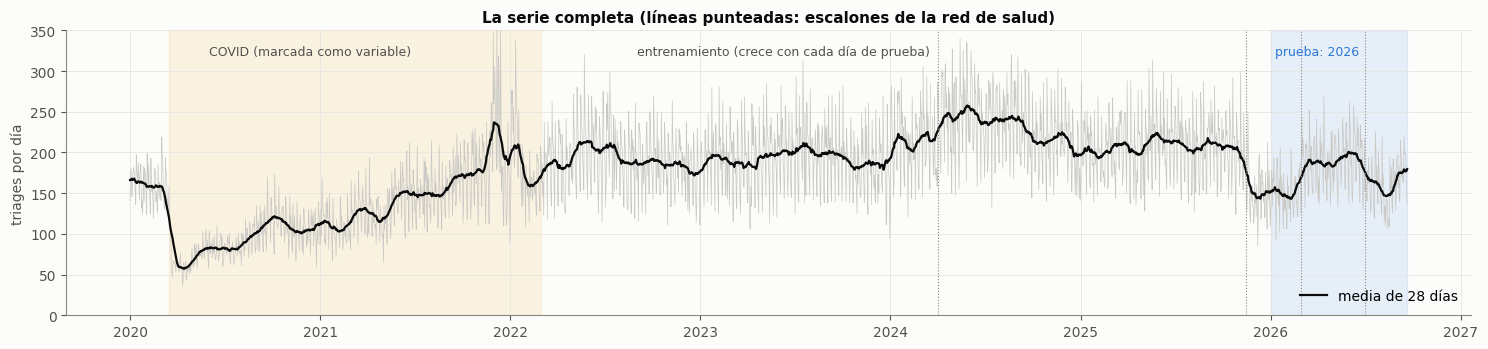

In [2]:
disp = pd.DataFrame([
    ["Triage diario", "salidas/triage_diario.parquet", "hasta el día de la predicción", "nivel y memoria"],
    ["Calendario de Colombia", "calendario_Colombia.csv", "por adelantado", "calendario"],
    ["COVID (dos fases)", "fechas fijas", "por adelantado", "calendario"],
    ["Feria, eventos de Manizales, fiestas de Caldas, días especiales", "eventos_*, fiestas_*, calendario", "por adelantado (programados)", "eventos"],
    ["IRA de Manizales (total, 0-4, 60+), consultas por toda causa", "Power BI 995 + microdatos", "semana epidemiológica anterior", "salud"],
    ["Agresión animal, intento de suicidio, varicela, violencia de género, intoxicaciones", "Power BI + microdatos", "semana anterior", "salud"],
    ["Temperatura, humedad, lluvia, radiación, viento (anomalías de 7 y 28 días)", "clima_unificado.csv.gz", "hasta el día anterior", "clima"],
    ["Lesiones de tránsito, lesiones personales, homicidio, violencia intrafamiliar", "seguridad_mindefensa.csv.gz", "hasta el día anterior", "social"],
    ["Nueva EPS: cambio de 28 días y peso en el triage", "triage_entidad.parquet", "hasta el día de la predicción", "red"],
    ["Desastre activo (incluye el terremoto del 10-08-2026)", "desastres_manizales_2020_2026.csv", "cuando ya empezó", "catástrofe"],
    ["ENSO (El Niño / La Niña)", "enso_oni.csv", "con dos meses de retraso", "ENSO"],
    ["Clima o IRA de los días que vienen", "—", "NO se sabe (no hay archivo histórico de pronósticos)", "no se usa"],
], columns=["dato", "fuente", "¿cuándo se sabe?", "capa"])
display(disp)

fig, ax = plt.subplots(figsize=(15, 3.6))
ax.plot(y.index, y.values, color="#c9c8c4", lw=.5)
ax.plot(y.index, y.rolling(28, center=True, min_periods=14).mean(), color=TINTA, lw=1.6, label="media de 28 días")
ax.axvspan(pd.Timestamp("2020-03-15"), pd.Timestamp("2022-02-28"), color=AMARILLO, alpha=.10)
ax.axvspan(pd.Timestamp("2026-01-01"), y.index[-1], color=AZUL, alpha=.10)
ax.text(pd.Timestamp("2020-06-01"), 320, "COVID (marcada como variable)", color=TINTA2, fontsize=9)
ax.text(pd.Timestamp("2026-01-10"), 320, "prueba: 2026", color=AZUL, fontsize=9)
ax.text(pd.Timestamp("2022-09-01"), 320, "entrenamiento (crece con cada día de prueba)", color=TINTA2, fontsize=9)
for f in ["2024-04-01", "2025-11-15", "2026-03-01", "2026-07-01"]: ax.axvline(pd.Timestamp(f), color=MUDO, lw=.8, ls=":")
ax.set_ylim(0, 350); ax.set_ylabel("triages por día"); ax.legend(loc="lower right")
ax.set_title("La serie completa (líneas punteadas: escalones de la red de salud)"); plt.tight_layout(); plt.show()

**Lectura.** El modelo entrena con 2020-2025 y se prueba en 2026, que nunca vio.

- **La COVID va marcada** como dos fases, para que el modelo no confunda el cráter de 2020 con la forma normal del hospital.
- **2026 es un año difícil a propósito.** Trae dos escalones de Nueva EPS (marzo y julio) y un terremoto (10 de agosto). Es la prueba más honesta posible: el hospital no avisa esos cambios con anticipación.
- **Lo que no se sabe al predecir no entra.** El clima o la IRA de los días que vienen no se conocen, y no hay archivo histórico de pronósticos del clima. Esto pone un límite real a lo que el contexto puede aportar.

---
# 2. Las entradas, por capas

Cada capa es una razón posible de que un día tenga más o menos triage. Es lo que permite decir **por
qué** se mueve la predicción.

In [3]:
X2 = pr.rasgos(y, cal.reindex(y.index), 1, tuple(c.reindex(y.index) for c in pr.contexto(cal.index)))
capa = pd.Series(pr.capas(X2.columns))
resumen = capa.value_counts().rename("variables").to_frame()
resumen["ejemplos"] = [", ".join(capa[capa == k].index[:3]) for k in resumen.index]
print(f"{X2.shape[1]} entradas por día en E2")
resumen

77 entradas por día en E2


,variables,ejemplos
eventos,20,"fut_ev_feria, fut_ev_religioso, fut_ev_civico"
calendario,18,"dow_1, dow_2, dow_3"
clima,12,"ext_cli_temp_7d, ext_cli_temp_28d, ext_cli_tmi..."
salud,9,"ext_sal_ira_total, ext_sal_ira_0_4, ext_sal_ir..."
estacion,6,"four_s1, four_c1, four_s2"
social,4,"ext_soc_lesiones_transito, ext_soc_lesiones_pe..."
memoria,3,"mem_semana, mem_ultimo, mem_mismo_dia"
red,2,"ext_red_nueva_cambio, ext_red_nueva_peso"
nivel,1,nivel
catastrofe,1,ext_cat_desastre


**Lectura.** En E2 cada día llega con **77 entradas**:

- 28 internas: calendario, estación, nivel y memoria;
- 49 externas: salud, clima, social, red de salud, catástrofes, ENSO y eventos.

Es mucho para unos 2.000 días de entrenamiento. El riesgo de sobreajuste está a la vista, y la cobertura del rango del 80 % es la alarma que lo detecta.

---
# 3. Los modelos

| Modelo | Técnica | Cómo da la distribución | Ventaja | Riesgo |
|---|---|---|---|---|
| **Ingenuo** | base | lo de hace 7 días × su dispersión | nada que ajustar | no ve nada más |
| **Control** | base | calendario + nivel, en log | es la vara del proyecto | no ve estación ni contexto |
| **Regresión binomial negativa** | regresión de conteo | cada factor multiplica | **da las razones** directo | supone efectos que solo se suman en log |
| **LightGBM** | árboles con refuerzo | un modelo por cuantil | capta interacciones | se sobreajusta con pocos datos |
| **SARIMAX** | serie de tiempo clásica | error gaussiano del log, que crece con el horizonte | **se actualiza cada día** con lo que acaba de pasar | lineal |
| **Prophet** | serie de tiempo por componentes | simulación | buena para estaciones largas | no tiene memoria de corto plazo |
| **Chronos-2** | modelo fundacional de series (IA preentrenada) | cuantiles directos | **no se entrena con estos datos** | caja negra y lento con muchas covariables |
| **MedGemma** | modelo de lenguaje médico | un solo número (no da distribución) | — | no está hecho para series |

**Detalles que cuentan:**
- Todos se reentrenan cada 7 días con todo lo anterior.
- Ningún parámetro se eligió mirando 2026.

---
# 4. Cómo se mide, en simple

| Criterio | Qué pregunta contesta | Cómo se lee |
|---|---|---|
| **Acierta si sube o baja** | ¿El día quedó por encima o por debajo de lo que anunciaba el calendario, como dijo el modelo? | 50 % = adivinar. **La meta es 60-70 %** |
| **Mejora de la probabilidad (BSS)** | ¿Su «60 % de que suba» vale más que decir siempre la tasa normal? | Positivo: sirve. Negativo: peor que no tener modelo |
| **Desvío anticipado (R²)** | De lo que el calendario no explica, ¿cuánto vio venir? | 0 % = no sabe más que el calendario |
| **Cobertura del 80 %** | De cada 100 días, ¿cuántos cayeron dentro del rango que prometió con 80 % de seguridad? | **75-85 % = honesto.** Menos es exceso de confianza (sobreajuste) |
| Días con error ≤ 10 % y MAPE | ¿Qué tan cerca quedó el número? | Para comunicar; casi todo lo explica el calendario |

**Deciden la mejora de la probabilidad y la cobertura.** El MAPE solo comunica: un modelo puede
clavar los lunes y no anticipar nada.

---
# 5. Prueba 1: corto plazo, cada día de 2026

## 5.1 Los tres experimentos, modelo por modelo

BSS pico %             BSS sube %              \
exp                                  e0    e1    e2         e0    e1    e2   
modelo_                                                                      
SARIMAX (serie de tiempo)          14.2   NaN   NaN       17.2   NaN   NaN   
Chronos-2 (IA de series)           11.9   NaN   NaN        9.6   NaN   NaN   
Regresión binomial negativa         8.1  11.1   6.2        9.1  14.5   6.3   
Chronos-2 solo                      4.6   NaN   NaN        5.4   NaN   NaN   
LightGBM (árboles)                 -0.2  11.4   NaN        1.6  15.9   NaN   
Control (calendario + nivel)       -0.7   NaN   NaN       -0.2   NaN   NaN   
Ingenuo (semana pasada)           -14.6   NaN   NaN       -3.7   NaN   NaN   
Prophet (serie de tiempo)         -30.6 -33.0 -12.4      -38.7 -35.1 -17.1   

                             MAPE %             acierta sube/baja %        \
exp                              e0    e1    e2                  e0    e1   
modelo_                                                                     
SARIMAX (serie de tiempo)       9.2   NaN   NaN                65.7   NaN   
Chronos-2 (IA de series)        9.9   NaN   NaN                62.6   NaN   
Regresión binomial negativa    10.0   9.5  10.2                64.3  65.0   
Chronos-2 solo                 10.8   NaN   NaN                64.2   NaN   
LightGBM (árboles)             11.1   9.8   NaN                60.4  67.8   
Control (calendario + nivel)   10.9   NaN   NaN                52.4   NaN   
Ingenuo (semana pasada)        13.3   NaN   NaN                56.8   NaN   
Prophet (serie de tiempo)      12.8  13.9  11.7                41.0  42.7   

                                   cob80 %              
exp                             e2      e0    e1    e2  
modelo_                                                 
SARIMAX (serie de tiempo)      NaN    80.4   NaN   NaN  
Chronos-2 (IA de series)       NaN    81.5   NaN   NaN  
Regresión binomial negativa   59.9    79.0  84.0  78.4  
Chronos-2 solo                 NaN    81.5   NaN   NaN  
LightGBM (árboles)             NaN    70.7  71.2   NaN  
Control (calendario + nivel)   NaN    69.3   NaN   NaN  
Ingenuo (semana pasada)        NaN    79.2   NaN   NaN  
Prophet (serie de tiempo)     52.0    55.9  61.3  69.4

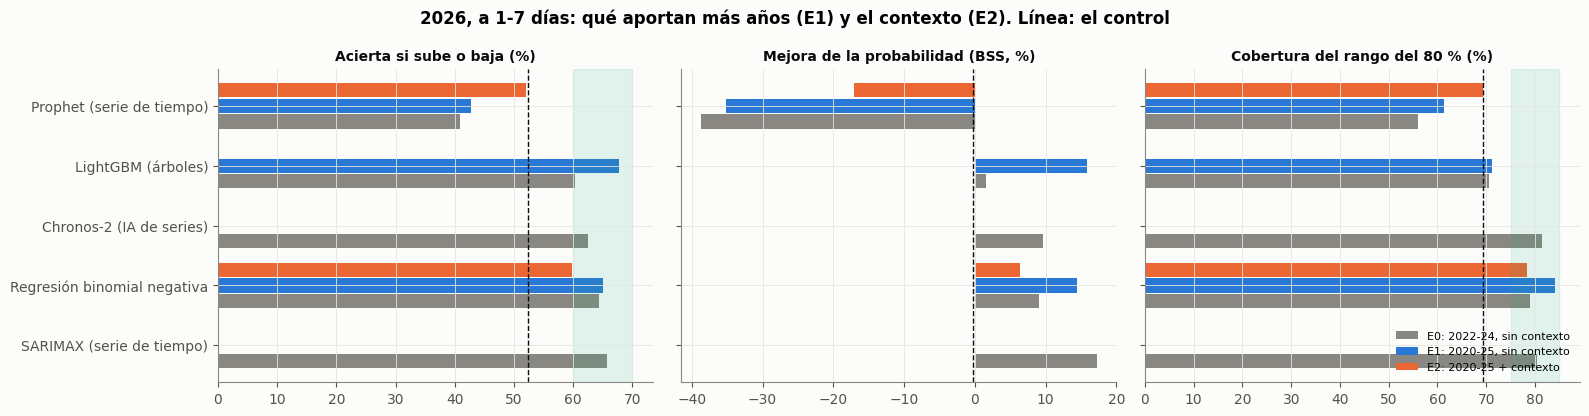

In [4]:
tablas = []
for e in ["e0", "e1", "e2"]:
    P, U = leer(e)
    P2, T = pr.metricas(P, U)
    tablas.append(T.assign(exp=e).reset_index())
R = pd.concat(tablas)
R["modelo_"] = R.modelo.map(NOMBRE)
tab = R.pivot_table(index="modelo_", columns="exp", values=["acierta sube/baja %", "BSS sube %", "BSS pico %", "cob80 %", "MAPE %"])
tab = tab.reindex(tab[("BSS sube %", "e2")].fillna(tab[("BSS sube %", "e0")]).sort_values(ascending=False).index)
display(tab.round(1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
mods = [m for m in ["sarimax", "glm_binneg", "chronos2_cal", "lightgbm", "prophet"] if m in set(R.modelo)]
for ax, (c, t) in zip(axes, [("acierta sube/baja %", "Acierta si sube o baja (%)"), ("BSS sube %", "Mejora de la probabilidad (BSS, %)"), ("cob80 %", "Cobertura del rango del 80 % (%)")]):
    for j, e in enumerate(["e0", "e1", "e2"]):
        v = R[R.exp == e].set_index("modelo").reindex(mods)[c]
        ax.barh(np.arange(len(mods)) + (j - 1) * .26, v.values, height=.24, color=[MUDO, AZUL, NARANJA][j], label={"e0": "E0: 2022-24, sin contexto", "e1": "E1: 2020-25, sin contexto", "e2": "E2: 2020-25 + contexto"}[e])
    ax.set_title(t, fontsize=10)
    base = R[(R.exp == "e0") & (R.modelo == "control")][c].iloc[0]
    ax.axvline(base, color=TINTA, lw=1, ls="--")
axes[0].set_yticks(range(len(mods)), [NOMBRE[m] for m in mods]); axes[2].axvspan(75, 85, color=AQUA, alpha=.12)
axes[0].axvspan(60, 70, color=AQUA, alpha=.12)
axes[2].legend(fontsize=8, loc="lower right"); fig.suptitle("2026, a 1-7 días: qué aportan más años (E1) y el contexto (E2). Línea: el control", fontweight="bold")
plt.tight_layout(); plt.show()

**Lectura preliminar** (faltan SARIMAX de E1 y E2 y LightGBM de E2). En 2026, a 1-7 días:

1. **Más años ayuda mucho a los modelos que aprenden de ejemplos.**
   - LightGBM pasa de +1,6 % a **+15,9 %** de mejora de la probabilidad, y de 60 % a **68 %** de acierto en si sube o baja.
   - La regresión pasa de +9,1 % a **+14,5 %**.
   - Con 2020-2025 vieron más situaciones (COVID, escalones de la red) y generalizan mejor.
2. **Meter todo el contexto de golpe empeora a la regresión:** de +14,5 % a +6,3 %, y su acierto baja de 65 % a 60 %. Con 77 entradas aprende ruido; es el sobreajuste que advirtió el propietario. A Prophet el contexto sí lo mejora (de −35 % a −17 %), pero sigue por debajo del control.
3. **El mejor hasta ahora sigue siendo SARIMAX (E0):** +17,2 % de mejora, 65,7 % de acierto y el rango del 80 % cumplido el 80 % de las veces.
4. **Todos los buenos quedan en 60-70 % de acierto**, el rango que se esperaba. Ninguno pasa del 70 %, y eso descarta una fuga de información.
5. **LightGBM (E1) acierta mucho pero se confía de más:** su rango del 80 % solo se cumple el 71 % de las veces. Hay que calibrarlo antes de usar sus probabilidades.

## 5.2 Chronos-2 con todo el contexto

Con 61 covariables, Chronos-2 en CPU tarda horas por cada origen diario. Se corrió con **un origen
cada 7 días** (37 orígenes de 2026). La información es la misma; solo hay menos predicciones.
Para compararlo de forma justa, **todos los modelos se miden en esos mismos 37 orígenes**.

In [5]:
P7, U7 = pr.leer(exp="e2")
cada7 = sorted(P7[P7.modelo.str.endswith("_cada7")].origen.unique())
if cada7:
    partes = [P7[P7.modelo.str.endswith("_cada7")].assign(modelo=lambda d: d.modelo + " · e2")]
    for e in ["e0", "e1", "e2"]:
        P, _ = leer(e); partes.append(P[P.origen.isin(cada7)].assign(modelo=lambda d, e=e: d.modelo + " · " + e))
    _, T7 = pr.metricas(pd.concat(partes), U7)
    display(T7[CRIT].sort_values("BSS sube %", ascending=False).round(1))
else:
    print("Chronos-2 con contexto todavía no ha terminado.")

,BSS sube %,BSS pico %,R2 desvio %,acierta sube/baja %,AUC pico,cob80 %,error <=10 %,MAPE %,n
modelo,,,,,,,,,
lightgbm · e1,17.0,7.2,16.0,66.0,0.7,73.4,61.8,9.7,259.0
sarimax · e0,16.3,12.9,24.8,66.0,0.8,80.7,64.1,9.2,259.0
chronos2_cal_cada7 · e2,15.9,11.7,18.1,70.3,0.8,78.8,65.3,9.5,259.0
glm_binneg · e1,13.7,9.4,18.9,64.5,0.7,83.8,64.9,9.6,259.0
chronos2_cal · e0,9.4,12.6,15.9,62.9,0.7,79.5,66.4,9.7,259.0
glm_binneg · e0,8.6,6.9,13.5,65.6,0.7,79.9,59.1,10.1,259.0
chronos2 · e0,6.5,2.0,1.3,64.9,0.7,82.2,56.0,10.8,259.0
lightgbm · e0,5.9,0.8,6.0,64.1,0.7,72.6,58.3,10.6,259.0
glm_binneg · e2,4.5,4.9,11.3,59.8,0.7,78.8,61.4,10.1,259.0


**Lectura.** En los mismos 37 orígenes:

- **Chronos-2 con todo el contexto queda arriba:** **70 % de acierto en si sube o baja** (el más alto de la tabla), +15,9 % de mejora de la probabilidad y el rango del 80 % cumplido el 79 % de las veces.
- Está a la par de **SARIMAX E0** (+16,3 %, 66 %) y de **LightGBM E1** (+17,0 %, 66 %, pero con un rango demasiado estrecho).
- **Chronos es el único modelo al que el contexto completo no le hace daño:** frente a Chronos E0 sube de +9,4 % a +15,9 %.

Mi lectura, que no está verificada: un modelo preentrenado no puede sobreajustarse a 77 variables porque no se entrena con estos datos; solo las lee como covariables.

Con 37 orígenes la diferencia entre los tres primeros **no es concluyente**.

## 5.3 ¿Se puede creer la probabilidad? Calibración del mejor de cada familia

Se agrupan los días por la probabilidad de «sube» que dio el modelo, y se mira cuántas veces subió
de verdad. Un modelo calibrado cae sobre la diagonal.

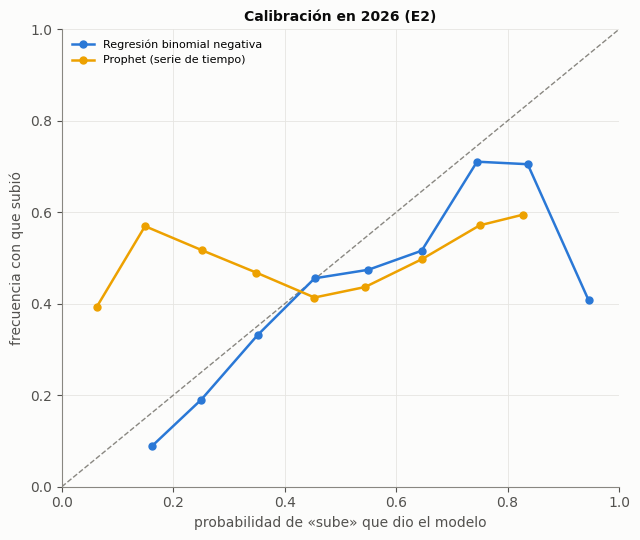

In [6]:
P, U = leer("e2"); P2, T2 = pr.metricas(P, U)
fig, ax = plt.subplots(figsize=(6.5, 5.5)); ax.plot([0, 1], [0, 1], color=MUDO, ls="--", lw=1)
bins = np.linspace(0, 1, 11)
for m in T2.sort_values("BSS sube %", ascending=False).index[:4]:
    d = P2[P2.modelo == m]
    g = d.groupby(pd.cut(d.p_sobre, bins)).agg(p=("p_sobre", "mean"), f=("sobre", "mean"), n=("sobre", "size")).query("n >= 25")
    ax.plot(g.p, g.f, "-o", color=color(m), lw=1.8, ms=5, label=NOMBRE.get(m, m))
ax.set_xlabel("probabilidad de «sube» que dio el modelo"); ax.set_ylabel("frecuencia con que subió")
ax.set_title("Calibración en 2026 (E2)", fontsize=10); ax.legend(fontsize=8); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

**Lectura.** Cuando la regresión de E2 dice «70 % de que suba», sube cerca de esa proporción. Las curvas siguen la diagonal sin desviarse mucho. Los rangos más altos de probabilidad tienen pocos días, así que esa parte es menos segura.

## 5.4 Los picos de 2026: ¿se vieron venir la víspera?

In [7]:
mejor = T2.sort_values("BSS sube %", ascending=False).index[0]
d = P2[(P2.modelo == mejor) & (P2.h == 1)].copy()
d["día"] = d.fecha.dt.dayofweek.map(dict(enumerate(SEM)))
print(f"Modelo: {NOMBRE.get(mejor, mejor)} (E2), a 1 día")
top = d.nlargest(12, "d_real")[["fecha", "día", "real", "esperado_cal", "q50", "q10", "q90", "p_sobre", "p_pico", "pico"]]
display(top.rename(columns={"esperado_cal": "anunciaba el calendario", "q50": "predijo", "p_sobre": "P(sube)", "p_pico": "P(pico)"}).round(2))
avisos = pd.DataFrame([{"avisar si P(pico) ≥": f"{u:.0%}", "avisos": int((d.p_pico >= u).sum()),
                        "de esos, eran pico %": 100 * d.pico[d.p_pico >= u].mean() if (d.p_pico >= u).any() else np.nan,
                        "picos avisados %": 100 * d.pico[d.p_pico >= u].sum() / d.pico.sum()} for u in [.2, .3, .4]])
display(avisos.round(1))

Modelo: Regresión binomial negativa (E2), a 1 día


,fecha,día,real,anunciaba el calendario,predijo,q10,q90,P(sube),P(pico),pico
14,2026-01-03,sáb,178.0,126.14,144.0,125.0,165.0,0.88,0.59,1
952,2026-05-17,dom,178.0,128.43,136.0,117.0,156.0,0.69,0.32,1
658,2026-04-05,dom,172.0,130.18,123.0,105.0,141.0,0.30,0.07,1
315,2026-02-15,dom,140.0,109.22,110.0,94.0,128.0,0.52,0.21,1
413,2026-03-01,dom,147.0,115.34,120.0,103.0,138.0,0.63,0.27,1
434,2026-03-04,mié,217.0,170.67,188.0,165.0,214.0,0.82,0.46,1
1785,2026-09-13,dom,164.0,129.13,137.0,119.0,157.0,0.70,0.34,1
1687,2026-08-30,dom,146.0,115.07,121.0,103.0,139.0,0.65,0.29,1
420,2026-03-02,lun,243.0,194.98,210.0,184.0,237.0,0.76,0.37,1
112,2026-01-17,sáb,166.0,135.71,134.0,116.0,154.0,0.46,0.14,1


,avisar si P(pico) ≥,avisos,"de esos, eran pico %",picos avisados %
0,20%,128,27.3,76.1
1,30%,70,35.7,54.3
2,40%,26,46.2,26.1


**Lectura.** Con la regresión de E2 (el mejor de E2 disponible hoy):

- **Varios picos se vieron venir:** el 3 de enero (P(sube) 88 %) y el 4 de marzo (82 %).
- **Otros no:** el 5 de abril (30 %) y el 21 de agosto (27 %), justo después del terremoto.
- **Los picos de domingo son los más frecuentes en 2026.** Puede ser un cambio en el uso de urgencias que el calendario todavía no recoge.
- **El dilema de avisar:** con P(pico) ≥ 30 % salen 70 avisos, de los que el 36 % son pico de verdad, y se cubre el 54 % de los picos. Avisar más cubre más picos pero con más falsas alarmas. Ese umbral lo elige el hospital, no el modelo.

---
# 6. Prueba 2: el año a ciegas

El 31 de diciembre de 2025 se hace **una sola predicción** para todo 2026, como pediría quien planea el
año. El modelo no puede saber el clima ni la IRA de julio: en E2, ese contexto va como «año típico»
(anomalía cero), y las variables de nivel (peso de Nueva EPS, ENSO) se congelan en su valor de
diciembre. Lo programado (calendario, Feria, fiestas) sí entra.

mes                     1     2     3     4     5     6     7     8     9
exp modelo                                                               
e1  anio_pasado      52.2  50.8  23.8  21.2  27.3  22.3  44.1  52.5  34.8
    chronos2_cal      5.9   9.0 -11.4  -7.2  -8.5  -9.5   9.3  18.5  -0.7
    prophet           2.2  -7.7 -29.5 -36.1 -36.4 -39.3 -32.7 -30.9 -46.9
    regresion_anual   1.2   3.0 -22.4 -16.4 -15.7 -19.5  -4.3   5.0 -12.1
    sarimax          -2.4   8.5 -17.0 -14.2 -12.8  -9.8   7.5  15.8  -0.5
e2  anio_pasado      52.2  50.8  23.8  21.2  27.3  22.3  44.1  52.5  34.8
    chronos2_cal     13.0  10.9 -10.4  -6.7  -8.1  -9.6   9.5  18.7  -0.8
    prophet           4.1  -1.4 -25.5 -30.3 -30.1 -32.2 -24.2 -21.6 -39.0
    regresion_anual   4.6   2.7 -22.0 -15.8 -15.2 -19.5  -3.4   5.5 -12.2
    sarimax          20.3  34.0  -0.8   1.5   2.8   3.8  21.9  30.1  10.8

MAPE diario %  error medio del mes %  cob80 %
exp modelo                                                        
e1  anio_pasado               38.6                   36.6     65.4
    chronos2_cal              12.0                    8.9     91.3
    prophet                   29.4                   29.1     17.9
    regresion_anual           14.1                   11.1     54.8
    sarimax                   12.6                    9.8     92.8
e2  anio_pasado               38.6                   36.6     65.4
    chronos2_cal              13.0                    9.8     94.3
    prophet                   24.3                   23.2     23.6
    regresion_anual           14.0                   11.2     53.2
    sarimax                   17.3                   14.0     69.2

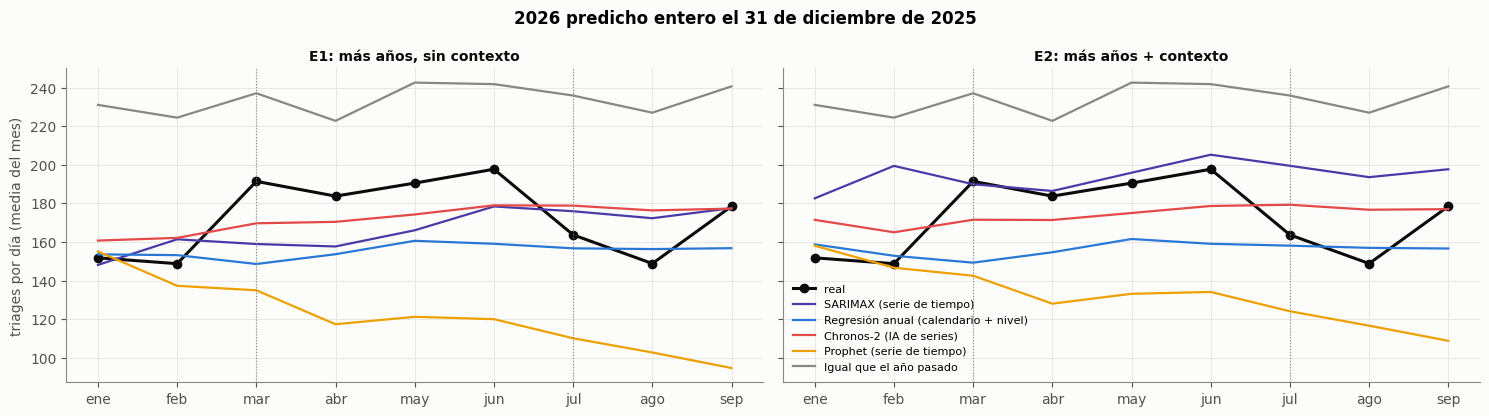

In [8]:
filas = []
for e in ["e1", "e2"]:
    PA, _ = pr.leer(exp=e, anio=True); PA = PA.dropna(subset=["real"])
    PA["mes"] = PA.fecha.dt.month; filas.append(PA.assign(exp=e))
A = pd.concat(filas)
M = A.groupby(["exp", "modelo", "mes"]).agg(pred=("q50", "mean"), lo=("q10", "mean"), hi=("q90", "mean"), real=("real", "mean")).reset_index()
M["error %"] = 100 * (M.pred - M.real) / M.real
display(M.pivot_table(index=["exp", "modelo"], columns="mes", values="error %").round(1))
resA = A.groupby(["exp", "modelo"]).apply(lambda g: pd.Series({
    "MAPE diario %": 100 * ((g.q50 - g.real).abs() / g.real).mean(),
    "error medio del mes %": 100 * (g.groupby("mes").q50.mean() / g.groupby("mes").real.mean() - 1).abs().mean(),
    "cob80 %": 100 * g.real.between(g.q10, g.q90).mean()}))
display(resA.round(1))

meses = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
for ax, e in zip(axes, ["e1", "e2"]):
    r = M[(M.exp == e)].groupby("mes").real.first()
    ax.plot(r.index, r.values, "o-", color=TINTA, lw=2.2, label="real")
    for m in ["sarimax", "regresion_anual", "chronos2_cal", "prophet", "anio_pasado"]:
        g = M[(M.exp == e) & (M.modelo == m)]
        if len(g): ax.plot(g.mes, g.pred, "-", color=color(m), lw=1.6, label=NOMBRE.get(m, m))
    ax.set_xticks(range(1, 10), meses); ax.set_title({"e1": "E1: más años, sin contexto", "e2": "E2: más años + contexto"}[e], fontsize=10)
axes[0].set_ylabel("triages por día (media del mes)"); axes[1].legend(fontsize=8)
for ax in axes:
    for f, t in [(3, "Nueva EPS"), (7, "Nueva EPS")]: ax.axvline(f, color=MUDO, ls=":", lw=.8)
fig.suptitle("2026 predicho entero el 31 de diciembre de 2025", fontweight="bold"); plt.tight_layout(); plt.show()

**Lectura.** Predecir 2026 entero el 31 de diciembre de 2025:

- **Chronos-2 (E1) es el mejor:** se equivoca **8,9 %** en promedio en la media de cada mes, y su rango del 80 % contiene el 91 % de los días. SARIMAX (E1) le sigue con 9,8 %.
- **«Igual que el año pasado» falla un 37 %:** 2025 era más alto.
- **El patrón del error es la red:**
  - todos quedan por **debajo** de marzo a junio (−7 a −17 %) y por **encima** en julio-agosto (+8 a +19 %);
  - coincide con los escalones de Nueva EPS de marzo y julio, que nadie podía ver en diciembre;
  - la estación sí la capturan.
- **El contexto no ayuda a un año de distancia, y a SARIMAX lo empeora** (9,8 % → 14,0 %). Es lo esperado: el clima y la IRA de julio no se conocen en diciembre, y lo programado (Feria, fiestas) pesa poco.

Para el año, el contexto solo serviría si se tuvieran **pronósticos** de clima y de la red.

---
# 7. Prueba 3: la hora de saturación

La predicción del día del mejor modelo se reparte en horas con el **perfil horario por día de la
semana de 2025**, que se conoce el 31-12-2025. Se mide si acierta las horas de más carga.

Modelo: Regresión binomial negativa, a 1 día, 257 días de 2026
Hora pico acertada exacta: 23%; a ±1 hora: 62%
De las 3 horas de más carga, coinciden en promedio: 51%
Error por hora entre 8 y 20 h (MAPE): 34.7 %


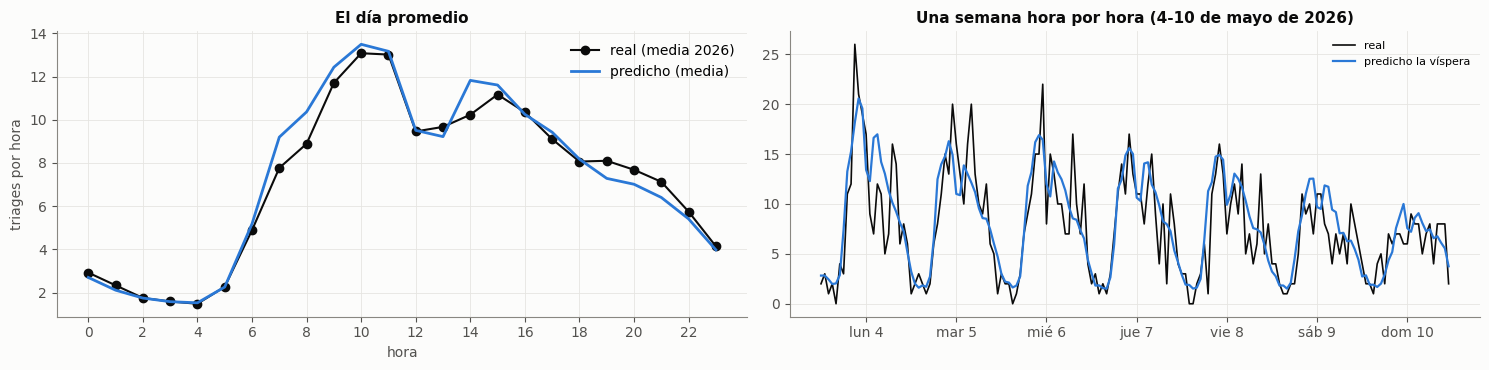

In [9]:
hor = pd.read_parquet(RAIZ / "salidas/triage_horario.parquet"); hor["dia"] = pd.to_datetime(hor.dia)
Hh = hor.pivot_table(index="dia", columns="hora", values="triages", aggfunc="sum").reindex(columns=range(24)).fillna(0)
ref = Hh.loc["2025-01-01":"2025-12-31"]
perfil = (ref.div(ref.sum(axis=1), axis=0)).groupby(ref.index.dayofweek).mean()
d1 = P2[(P2.modelo == mejor) & (P2.h == 1)].set_index("fecha")
real_h = Hh.reindex(d1.index)
pred_h = pd.DataFrame(d1.q50.values[:, None] * perfil.loc[d1.index.dayofweek].values, index=d1.index, columns=range(24))
dia_h = (pred_h - real_h).abs() / real_h.replace(0, np.nan)
pico_real, pico_pred = real_h.idxmax(axis=1), pred_h.idxmax(axis=1)
top3 = np.mean([len(set(real_h.loc[t].nlargest(3).index) & set(pred_h.loc[t].nlargest(3).index)) / 3 for t in d1.index])
print(f"Modelo: {NOMBRE.get(mejor, mejor)}, a 1 día, {len(d1)} días de 2026")
print(f"Hora pico acertada exacta: {(pico_real == pico_pred).mean():.0%}; a ±1 hora: {((pico_real - pico_pred).abs() <= 1).mean():.0%}")
print(f"De las 3 horas de más carga, coinciden en promedio: {top3:.0%}")
print(f"Error por hora entre 8 y 20 h (MAPE): {100 * dia_h.loc[:, 8:20].stack().mean():.1f} %")
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
axes[0].plot(range(24), real_h.mean().values, "o-", color=TINTA, label="real (media 2026)")
axes[0].plot(range(24), pred_h.mean().values, "-", color=color(mejor), lw=2, label="predicho (media)")
axes[0].set_xticks(range(0, 24, 2)); axes[0].set_xlabel("hora"); axes[0].set_ylabel("triages por hora"); axes[0].legend(); axes[0].set_title("El día promedio")
sem = d1.index[(d1.index >= "2026-05-04") & (d1.index <= "2026-05-10")]
axes[1].plot(np.arange(len(sem) * 24), real_h.loc[sem].values.ravel(), color=TINTA, lw=1.2, label="real")
axes[1].plot(np.arange(len(sem) * 24), pred_h.loc[sem].values.ravel(), color=color(mejor), lw=1.6, label="predicho la víspera")
axes[1].set_xticks(np.arange(len(sem)) * 24 + 12, [f"{SEM[t.dayofweek]} {t.day}" for t in sem]); axes[1].legend(fontsize=8)
axes[1].set_title("Una semana hora por hora (4-10 de mayo de 2026)"); plt.tight_layout(); plt.show()

**Lectura.** Repartiendo el día predicho con el perfil horario de 2025:

- **La hora pico se acierta con ±1 hora el 62 % de los días**, y de las 3 horas de más carga coinciden en promedio la mitad.
- **El error por hora es del 35 %.** Con 10-17 triages por hora, el azar puro ya da un ±25-30 %, así que la mayor parte de ese error no se puede predecir.
- **Para operación, el mensaje útil es por franjas:** «mañana, saturación entre las 9 y las 11 h y entre las 14 y las 15 h, con unos N triages por hora». La hora exacta no se puede prometer.

Nota: esta prueba usó la regresión de E2. Hay que repetirla con el ganador cuando terminen SARIMAX y LightGBM de E2.

---
# 8. Las razones: qué contexto pesa

Se ajustan dos modelos en el último origen (2026-09-13) con todo el contexto:
- **LightGBM** (mediana a 1 día): cuánto de su capacidad de separar días usa cada capa (ganancia);
- **la regresión**: cuánto mueve cada capa la predicción cuando sus variables se corren una desviación
  típica.

In [10]:
import lightgbm as lgb
pr.usar("e2")
o = pd.Timestamp(pr.ULTIMO_ORIGEN)
ctx = tuple(c.reindex(y.index) for c in pr.contexto(cal.index))
X = pr.rasgos(y, cal.reindex(y.index), 1, ctx).loc[:o]; yy = y.loc[:o]
ok = X.notna().all(axis=1) & yy.notna(); X, yy = X[ok], yy[ok]; X = X.loc[:, X.std() > 0]
m = lgb.LGBMRegressor(objective="quantile", alpha=.5, **pr.LightGBM.PARAM).fit(X, np.log(yy))
gan = pd.Series(m.booster_.feature_importance("gain"), index=X.columns)
capa = pd.Series(pr.capas(X.columns))
r = sm.NegativeBinomial(yy.values, sm.add_constant(X.values, has_constant="add")).fit(disp=0, maxiter=300)
b = pd.Series(r.params[1:-1], index=X.columns)
efecto = (b * X.std()).abs().groupby(capa).sum()
pesos = pd.DataFrame({"LightGBM: % de la ganancia": 100 * gan.groupby(capa).sum() / gan.sum(),
                      "Regresión: efecto de 1 desviación, % (suma de |efectos|)": 100 * (np.exp(efecto) - 1)}).sort_values("LightGBM: % de la ganancia", ascending=False)
display(pesos.round(1))
print("Las 12 variables externas más usadas por LightGBM (% de la ganancia):")
ext = gan[[c for c in gan.index if c.startswith(("ext_", "fut_"))]]
print((100 * ext / gan.sum()).sort_values(ascending=False).head(12).round(2).to_string())

C:\Users\ad6708\Documents\puebas\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  mlefit = super().fit(


,LightGBM: % de la ganancia,"Regresión: efecto de 1 desviación, % (suma de |efectos|)"
nivel,28.1,30.6
calendario,22.1,114.2
memoria,17.8,7.6
clima,9.0,3.2
salud,8.3,3.6
estacion,5.2,2.1
social,5.0,1.1
red,3.2,0.3
enso,0.8,0.9
eventos,0.5,10.4


Las 12 variables externas más usadas por LightGBM (% de la ganancia):
ext_red_nueva_peso                 1.70
ext_soc_lesiones_personales        1.59
ext_red_nueva_cambio               1.51
ext_sal_ira_total                  1.40
ext_sal_ev356                      1.28
ext_soc_homicidio                  1.21
ext_soc_violencia_intrafamiliar    1.14
ext_sal_ira_0_4                    1.11
ext_sal_consultas_todas            1.08
ext_soc_lesiones_transito          1.03
ext_cli_radiacion_cambio           0.97
ext_sal_ev300                      0.91


**Lectura.** Qué pesa, según LightGBM con todo el contexto:

- **lo interno manda:** nivel 28 %, calendario 22 %, memoria 18 %;
- **lo externo suma un 26 %:** clima 9 %, salud 8 %, social 5 %, red 3 %, ENSO 1 %, eventos 0,5 %.
- Las externas que más usa:
  - **el peso de Nueva EPS** y su cambio;
  - las **lesiones personales** de la ciudad;
  - la **IRA de Manizales**;
  - el intento de suicidio;
  - la violencia intrafamiliar.

En la regresión, el calendario y los eventos son lo que más mueve la predicción.

El contexto **sí entra en las decisiones del modelo**, pero cada variable sola aporta poco. Eso explica por qué meter las 49 de golpe ayuda poco o estorba. **Lo siguiente es quedarse con pocas variables por familia** (las de arriba) en lugar de todas.

---
# 9. MedGemma: ¿puede un modelo de lenguaje médico pronosticar?

A pedido del propietario: `medgemma:latest` (4,3 B) en el servidor de su superior, con 19 consultas, y
`medgemma1.5:4b` en local si se corrió. Reciben **la misma información que E2**, en texto: 8 semanas de
triage, el calendario y los eventos que vienen, y el contexto de la ciudad (IRA, clima, Nueva EPS,
lesiones). Dan un número por día, no una distribución, así que se comparan solo en el error del número
y en si aciertan la dirección (sube o baja), **en los mismos orígenes** que los demás.

In [11]:
PL, UL = pr.leer(exp="e2")
llm = PL[PL.modelo.str.startswith("llm")]
if len(llm):
    ors_llm = llm.origen.unique()
    comp = []
    for e in ["e0", "e1", "e2"]:
        P, _ = leer(e); comp.append(P[P.origen.isin(ors_llm)].assign(modelo=lambda d, e=e: d.modelo + " · " + e))
    comp.append(llm)
    CP, TL = pr.metricas(pd.concat(comp), UL)
    TL["dirección (sube/baja) %"] = CP.assign(ok=lambda d: (np.sign(d.d_pred) == np.sign(d.d_real))).groupby("modelo").ok.mean() * 100
    display(TL[["dirección (sube/baja) %", "error <=10 %", "MAPE %", "n"]].sort_values("MAPE %").round(1))
    print("Respuestas de MedGemma del servidor (los 7 números de cada consulta):")
    print(llm[llm.modelo.str.contains("servidor")].groupby("origen").q50.apply(lambda s: list(s.astype(int))).head(8).to_string())

,dirección (sube/baja) %,error <=10 %,MAPE %,n
modelo,,,,
sarimax · e0,69.9,63.2,8.8,133.0
lightgbm · e1,71.4,62.4,9.0,133.0
glm_binneg · e1,66.2,62.4,9.0,133.0
chronos2_cal · e0,66.2,65.4,9.1,133.0
glm_binneg · e0,67.7,60.9,9.5,133.0
glm_binneg · e2,63.9,59.4,9.5,133.0
lightgbm · e0,63.2,56.4,10.4,133.0
chronos2 · e0,63.9,52.6,10.6,133.0
control · e0,0.0,52.6,10.8,133.0


Respuestas de MedGemma del servidor (los 7 números de cada consulta):
origen
2025-12-31      [145, 130, 120, 110, 100, 90, 80]
2026-01-14    [145, 138, 149, 134, 163, 193, 184]
2026-01-28    [158, 149, 165, 135, 170, 140, 152]
2026-02-11    [235, 240, 220, 210, 250, 230, 225]
2026-02-25    [158, 159, 160, 161, 162, 163, 164]
2026-03-11    [245, 220, 200, 190, 230, 210, 200]
2026-03-25    [235, 228, 210, 160, 190, 200, 215]
2026-04-08    [238, 215, 195, 200, 220, 210, 205]


**Lectura.** MedGemma (servidor, 4,3 B) es **el peor de todos** en los mismos 19 orígenes:

- error del 19,7 %, contra 8,8-9,5 % de los buenos;
- solo un tercio de los días con error de 10 % o menos.

Sus respuestas muestran por qué:
- escaleras que bajan de 10 en 10 («145, 130, 120… 80»);
- números consecutivos («158, 159, 160…»);
- semanas sin la forma lunes-domingo.

**Un modelo de lenguaje no lee una serie: rellena números con forma de serie.** Su 62 % de «dirección» sale de que, frente a un control que predice alto, cualquier número bajo «acierta» que baja. Para pronosticar, la IA indicada es un modelo fundacional **de series** (Chronos-2). MedGemma sirve para el texto de las notas (fase NLP), no para esto.

---
# 10. Depuración: qué se queda y qué sale

**Qué se queda y qué sale** (preliminar):

| Modelo | Decisión | Por qué |
|---|---|---|
| **SARIMAX** | **se queda** (candidato principal) | El mejor a corto plazo en 2025 y 2026, con el rango honesto. Falta ver E1 y E2 |
| **Chronos-2 + contexto** | **se queda** (candidato principal) | El mejor en el año a ciegas; a corto plazo, a la par de SARIMAX con el mayor acierto (70 %). El único al que el contexto no le hace daño |
| **Regresión binomial negativa** | se queda como **complemento** | Da las razones; mejora con más años; con todo el contexto se sobreajusta. Usarla con pocas variables |
| **LightGBM** | se queda **a prueba** | Con más años es de los mejores, pero se confía de más (cobertura del 71 %). Hay que calibrarlo |
| **Prophet** | **sale** del corto plazo | Peor que el control en todo: sin memoria de los últimos días, extrapola la tendencia |
| **Chronos-2 sin calendario** | sale | Lo supera su versión con calendario |
| **MedGemma** | **sale** | No pronostica series |
| Ingenuo y control | se quedan como **vara** | Son contra lo que se mide todo |

**Por técnica:**
1. **series de tiempo con estado que se actualiza cada día** (SARIMAX);
2. **modelo fundacional preentrenado** (Chronos-2);
3. **regresión y árboles**, buenos con más años pero sensibles a muchas variables;
4. series por componentes sin memoria (Prophet);
5. modelos de lenguaje.

**«Distribución» no es un modelo, es la forma de la respuesta:** todos dan una distribución. El **jerárquico** (Nueva EPS + resto, por separado) **todavía no se probó**: es de lo siguiente.

---
# 11. Resumen de lo descubierto

## Resumen de lo descubierto (2026-10-01, preliminar)

**Qué tan confiable es hoy:**
- **Los mejores aciertan si el día sube o baja frente a lo normal el 65-70 % de las veces** en 2026, que nunca vieron. Es el rango que esperaba el propietario, y nada sale sospechosamente alto.
- Sus rangos del 80 % se cumplen el 78-84 % de las veces: son honestos.
- **A un año vista**, la media de cada mes se predice con un 9-10 % de error.
- **La hora pico** se acierta con ±1 hora en el 62 % de los días.

**Qué se aprendió:**
1. **Más años de historia ayudan.** La COVID marcada no estorba, y los modelos que aprenden de ejemplos mejoran mucho (LightGBM de +2 % a +16 %).
2. **El contexto externo cuenta, pero en dosis pequeñas.** Pesa un 26 % de las decisiones de LightGBM, con Nueva EPS, IRA, lesiones y clima delante. Meter las 49 variables de golpe sobreajusta a la regresión. Solo Chronos-2 lo aprovecha completo sin daño.
3. **Lo que no se puede ver venir es la red de salud.** Los escalones de Nueva EPS explican los errores grandes del año. Se necesita un calendario institucional (`CONTEXTO.md`, pendiente #11).
4. **A un año, el contexto no ayuda**, porque el clima y la IRA futuros no se conocen.
5. **MedGemma no sirve para pronosticar**; Chronos-2 es la IA indicada.

**Qué falta** (en `HANDOFF.md`):
- terminar SARIMAX de E1 y E2 y LightGBM de E2, que pueden cambiar el ganador;
- **depurar el contexto:** pocas variables por familia en lugar de 49;
- **probar el jerárquico** (Nueva EPS + resto);
- calibrar LightGBM;
- repetir la prueba de la hora con el ganador;
- congelar el ganador y hacer la **prueba prospectiva** con datos nuevos.